# Experiment 1



In [2]:
import pandas as pd

# Set USE_CSV = True to load your own CSV.
USE_CSV = False
CSV_PATH = "weather.csv"

def get_data():
    if USE_CSV:
        df = pd.read_csv(CSV_PATH)
    else:
        # Inbuilt categorical dataset: last column is the class label.
        df = pd.DataFrame([
            ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
            ["Sunny", "Warm", "High",   "Strong", "Warm", "Same", "Yes"],
            ["Rainy", "Cold", "High",   "Strong", "Warm", "Change", "No"],
            ["Sunny", "Warm", "High",   "Strong", "Cool", "Change", "Yes"],
            ["Rainy", "Warm", "Normal", "Weak",   "Cool", "Same", "No"],
        ], columns=["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"])
    return df

def find_s(X, y):
    positive = [row for row, label in zip(X, y) if str(label).lower() in ("yes", "1", "true")]
    if not positive:
        return ["Ø"] * X.shape[1]
    hypothesis = list(positive[0])
    for row in positive[1:]:
        for j, value in enumerate(row):
            if hypothesis[j] != value:
                hypothesis[j] = "?"
    return hypothesis

def candidate_elimination(X, y):
    n = X.shape[1]
    S = ["Ø"] * n
    G = [["?"] * n]

    def covers(h, x):
        return all(a == "?" or a == b for a, b in zip(h, x))

    for row, label in zip(X, y):
        positive = str(label).lower() in ("yes", "1", "true")
        row = list(row)

        if positive:
            G = [g for g in G if covers(g, row)]
            if S == ["Ø"] * n:
                S = row.copy()
            else:
                for j in range(n):
                    if S[j] != row[j]:
                        S[j] = "?"
            G = [g for g in G if covers(g, row)]
        else:
            new_G = []
            for g in G:
                if not covers(g, row):
                    new_G.append(g)
                    continue
                for j in range(n):
                    if S[j] == "?":
                        continue
                    if S[j] != "Ø" and S[j] != row[j]:
                        candidate = g.copy()
                        candidate[j] = S[j]
                        if covers(candidate, row) is False:
                            new_G.append(candidate)
            # Remove duplicates and hypotheses that are more specific than another G.
            unique = []
            for h in new_G:
                if h not in unique:
                    unique.append(h)
            G = unique

    return S, G

if __name__ == "__main__":
    df = get_data()
    X = df.iloc[:, :-1].astype(str).to_numpy()
    y = df.iloc[:, -1].astype(str).to_numpy()

    print("Dataset:\n", df.to_string(index=False))
    print("\nFind-S final hypothesis:", find_s(X, y))
    S, G = candidate_elimination(X, y)
    print("Candidate Elimination:")
    print("S (specific boundary):", S)
    print("G (general boundary):")
    for h in G:
        print(" ", h)


Dataset:
   Sky AirTemp Humidity   Wind Water Forecast EnjoySport
Sunny    Warm   Normal Strong  Warm     Same        Yes
Sunny    Warm     High Strong  Warm     Same        Yes
Rainy    Cold     High Strong  Warm   Change         No
Sunny    Warm     High Strong  Cool   Change        Yes
Rainy    Warm   Normal   Weak  Cool     Same         No

Find-S final hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
Candidate Elimination:
S (specific boundary): ['Sunny', 'Warm', '?', 'Strong', '?', '?']
G (general boundary):
  ['Sunny', '?', '?', '?', '?', '?']
  ['Sunny', 'Warm', '?', '?', '?', '?']
  ['?', 'Warm', '?', 'Strong', '?', '?']


# Experiment 2

In [22]:
import pandas as pd
from itertools import combinations

USE_CSV = False
CSV_PATH = "weather.csv"

def get_data():
    if USE_CSV:
        return pd.read_csv(CSV_PATH)
    return pd.DataFrame([
        ["Sunny", "Hot",  "High",   "Weak",   "No"],
        ["Sunny", "Hot",  "High",   "Strong", "No"],
        ["Overcast", "Hot", "High", "Weak",   "Yes"],
        ["Rain", "Mild", "High",    "Weak",   "Yes"],
        ["Rain", "Cool", "Normal",  "Weak",   "Yes"],
        ["Rain", "Cool", "Normal",  "Strong", "No"],
        ["Overcast", "Cool", "Normal", "Strong", "Yes"],
        ["Sunny", "Mild", "High",   "Weak",   "No"],
    ], columns=["Outlook", "Temperature", "Humidity", "Wind", "Play"])

def simple_rules(df):
    """Generate readable one-condition rules with perfect precision on this dataset."""
    target = df.columns[-1]
    features = list(df.columns[:-1])
    rules = []
    for feature in features:
        for value in df[feature].dropna().unique():
            subset = df[df[feature] == value]
            labels = subset[target].unique()
            if len(labels) == 1:
                rules.append(f"IF {feature} = {value} THEN {target} = {labels[0]}")
    return rules

def foil_gain(p0, n0, p1, n1):
    """FOIL information gain for a candidate literal."""
    import math
    if p1 == 0 or p0 == 0:
        return 0.0
    return p1 * (math.log2(p1 / (p1 + n1)) - math.log2(p0 / (p0 + n0)))

def foil_like_rules(df):
    """
    A compact FOIL-style learner for a categorical target:
    repeatedly add the attribute=value condition that best separates positive
    examples from negative examples. This is an educational simplified version,
    not a full first-order logic implementation.
    """
    target = df.columns[-1]
    positive_label = df[target].mode().iloc[0]
    positives = df[df[target] == positive_label]
    negatives = df[df[target] != positive_label]
    rules = []

    for _, example in positives.iterrows():
        conditions = []
        remaining_pos = positives.copy()
        remaining_neg = negatives.copy()
        available = list(df.columns[:-1])

        while len(remaining_neg) > 0 and available:
            best = None
            best_score = -1
            for col in available:
                value = example[col]
                p0, n0 = len(remaining_pos), len(remaining_neg)
                pos2 = remaining_pos[remaining_pos[col] == value]
                neg2 = remaining_neg[remaining_neg[col] == value]
                score = foil_gain(p0, n0, len(pos2), len(neg2))
                if len(pos2) and score > best_score:
                    best, best_score = (col, value, pos2, neg2), score
            if best is None:
                break
            col, value, remaining_pos, remaining_neg = best
            conditions.append(f"{col}={value}")
            available.remove(col)

        if conditions:
            rule = "IF " + " AND ".join(conditions) + f" THEN {target}={positive_label}"
            if rule not in rules:
                rules.append(rule)
    return rules

if __name__ == "__main__":
    df = get_data()
    print("Dataset:\n", df.to_string(index=False))
    print("\nExample-based categorical rules:")
    for rule in simple_rules(df):
        print(rule)
    print("\nFOIL-style learned rules:")
    for rule in foil_like_rules(df):
        print(rule)


Dataset:
  Outlook Temperature Humidity   Wind Play
   Sunny         Hot     High   Weak   No
   Sunny         Hot     High Strong   No
Overcast         Hot     High   Weak  Yes
    Rain        Mild     High   Weak  Yes
    Rain        Cool   Normal   Weak  Yes
    Rain        Cool   Normal Strong   No
Overcast        Cool   Normal Strong  Yes
   Sunny        Mild     High   Weak   No

Example-based categorical rules:
IF Outlook = Sunny THEN Play = No
IF Outlook = Overcast THEN Play = Yes

FOIL-style learned rules:
IF Outlook=Sunny THEN Play=No
IF Wind=Strong AND Outlook=Rain THEN Play=No


# Experiment 3

In [4]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

# Inbuilt dataset: Iris (150 samples, 4 numeric features, 3 classes).
# To use a CSV instead, replace this block with pd.read_csv("your_file.csv"),
# then set X = df.drop(columns=["target"]) and y = df["target"].
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)
bagging.fit(X_train, y_train)
bag_pred = bagging.predict(X_test)

print("=== BAGGING ===")
print("Accuracy:", round(accuracy_score(y_test, bag_pred), 3))
print(classification_report(y_test, bag_pred, target_names=iris.target_names, zero_division=0))

# Boosting
boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)
boosting.fit(X_train, y_train)
boost_pred = boosting.predict(X_test)

print("=== ADABOOST ===")
print("Accuracy:", round(accuracy_score(y_test, boost_pred), 3))
print(classification_report(y_test, boost_pred, target_names=iris.target_names, zero_division=0))


=== BAGGING ===
Accuracy: 0.921
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38

=== ADABOOST ===
Accuracy: 0.895
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



# Experiment 4

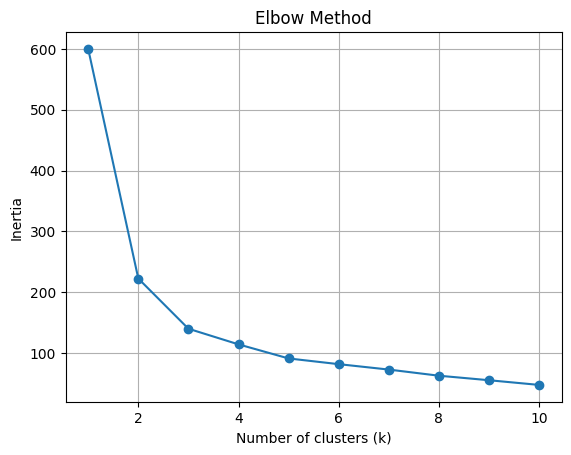

 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  Cluster
               5.1               3.5                1.4               0.2        1
               4.9               3.0                1.4               0.2        1
               4.7               3.2                1.3               0.2        1
               4.6               3.1                1.5               0.2        1
               5.0               3.6                1.4               0.2        1
               5.4               3.9                1.7               0.4        1
               4.6               3.4                1.4               0.3        1
               5.0               3.4                1.5               0.2        1
               4.4               2.9                1.4               0.2        1
               4.9               3.1                1.5               0.1        1


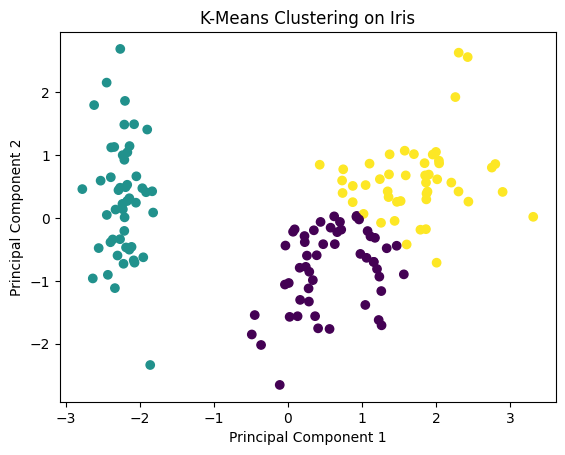

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Inbuilt Iris dataset. No CSV download required.
iris = load_iris(as_frame=True)
X = iris.data

# Scale numeric features before clustering.
X_scaled = StandardScaler().fit_transform(X)

# Elbow method: compare inertia for k = 1..10.
inertias = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

# Run final clustering. Change n_clusters to experiment.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

result = X.copy()
result["Cluster"] = clusters
print(result.head(10).to_string(index=False))

# PCA reduces four features to two dimensions for plotting.
points_2d = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=clusters)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on Iris")
plt.show()


# Experiment 5

In [7]:
!pip install minisom

  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=e6108932391510d63d1800a7d91d2f30bf9e4b5fa211b1b597ef83579a77f0fa
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


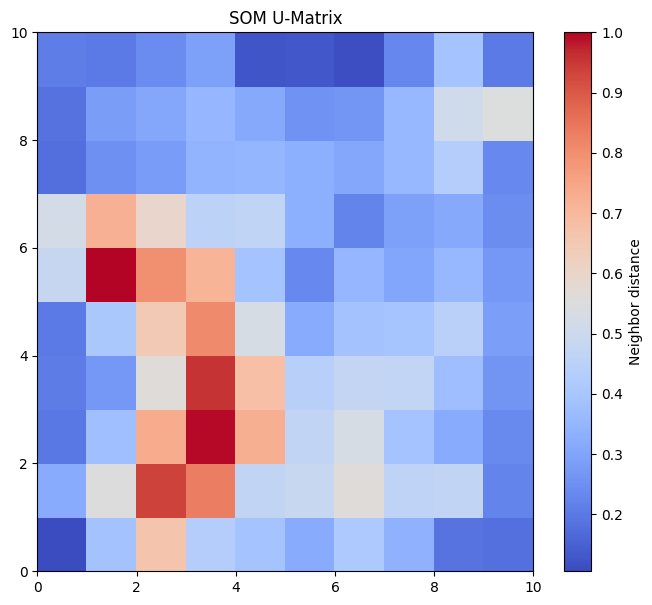

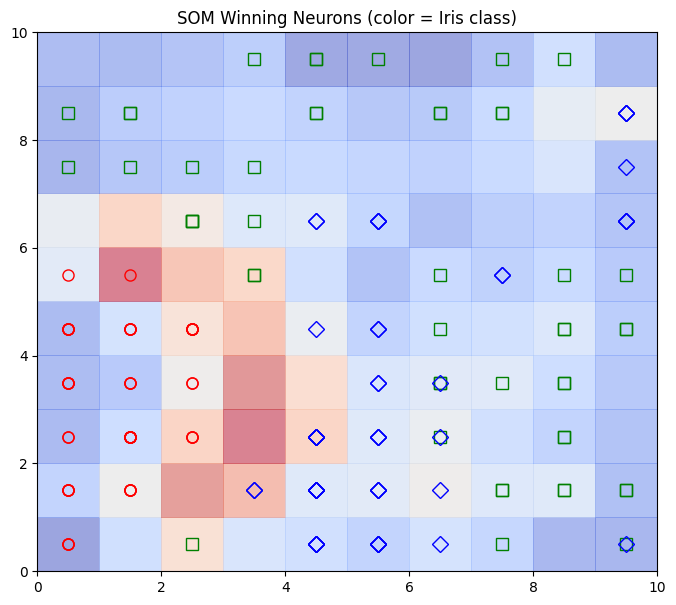

Sample 1: winning neuron = (np.int64(1), np.int64(2))
Sample 2: winning neuron = (np.int64(2), np.int64(4))
Sample 3: winning neuron = (np.int64(0), np.int64(4))
Sample 4: winning neuron = (np.int64(1), np.int64(4))
Sample 5: winning neuron = (np.int64(0), np.int64(3))
Sample 6: winning neuron = (np.int64(0), np.int64(0))
Sample 7: winning neuron = (np.int64(0), np.int64(4))
Sample 8: winning neuron = (np.int64(1), np.int64(3))
Sample 9: winning neuron = (np.int64(1), np.int64(4))
Sample 10: winning neuron = (np.int64(2), np.int64(4))


In [8]:
# Install first: pip install minisom scikit-learn matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

iris = load_iris()
X = iris.data
X_scaled = MinMaxScaler().fit_transform(X)

# Change grid dimensions, sigma, learning_rate, and iterations to experiment.
som = MiniSom(x=10, y=10, input_len=X_scaled.shape[1],
              sigma=1.0, learning_rate=0.5, random_seed=42)
som.random_weights_init(X_scaled)
som.train_random(X_scaled, num_iteration=1000)

# U-Matrix shows distances between neighboring SOM neurons.
plt.figure(figsize=(8, 7))
plt.pcolor(som.distance_map().T, cmap="coolwarm")
plt.colorbar(label="Neighbor distance")
plt.title("SOM U-Matrix")
plt.show()

# Plot each data point at its winning neuron; colors indicate Iris class.
plt.figure(figsize=(8, 7))
plt.pcolor(som.distance_map().T, cmap="coolwarm", alpha=0.5)
markers = ["o", "s", "D"]
colors = ["red", "green", "blue"]
for row, label in zip(X_scaled, iris.target):
    winner_x, winner_y = som.winner(row)
    plt.plot(winner_x + 0.5, winner_y + 0.5,
             markers[label], markerfacecolor="None",
             markeredgecolor=colors[label], markersize=8)
plt.title("SOM Winning Neurons (color = Iris class)")
plt.show()

# Print winning neuron for each sample.
for i, row in enumerate(X_scaled[:10]):
    print(f"Sample {i + 1}: winning neuron = {som.winner(row)}")


# Experiment 6

In [9]:
import random

def generate_uniform_samples(n):
    """Generate n random numbers uniformly distributed between 0 and 1."""
    return [random.uniform(0, 1) for _ in range(n)]

def f(x):
    # Edit this function to integrate a different expression.
    return x ** 2

def monte_carlo_integral(n=10):
    samples = generate_uniform_samples(n)
    values = [f(x) for x in samples]

    print("Sample\t x\t\t f(x)")
    for i, (x, value) in enumerate(zip(samples, values), start=1):
        print(f"{i}\t {x:.4f}\t\t {value:.4f}")

    # For integration over [0, 1], integral estimate is the mean of f(samples).
    estimate = sum(values) / n
    print(f"\nEstimated integral over [0, 1] = {estimate:.6f}")
    print("Exact integral for f(x)=x^2 is 1/3 =", round(1 / 3, 6))
    return estimate

if __name__ == "__main__":
    random.seed(42)  # Remove or change this to get different samples.
    n = 10            # Change the number of random samples here.
    monte_carlo_integral(n)


Sample	 x		 f(x)
1	 0.6394		 0.4089
2	 0.0250		 0.0006
3	 0.2750		 0.0756
4	 0.2232		 0.0498
5	 0.7365		 0.5424
6	 0.6767		 0.4579
7	 0.8922		 0.7960
8	 0.0869		 0.0076
9	 0.4219		 0.1780
10	 0.0298		 0.0009

Estimated integral over [0, 1] = 0.251772
Exact integral for f(x)=x^2 is 1/3 = 0.333333


# Experiment 7

In [11]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.8 MB/s eta 0:00:00


In [18]:

import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

# Step 1: Create an inbuilt dataset
data = pd.DataFrame({
    "Rain": [
        "Yes", "Yes", "No", "No", "Yes",
        "No", "Yes", "No", "Yes", "No"
    ],
    "Traffic": [
        "Yes", "Yes", "No", "Yes", "Yes",
        "No", "No", "No", "Yes", "No"
    ],
    "Late": [
        "Yes", "Yes", "No", "Yes", "Yes",
        "No", "No", "No", "Yes", "No"
    ]
})


# Step 2: Define the Bayesian Network structure
model = DiscreteBayesianNetwork([
    ("Rain", "Traffic"),
    ("Traffic", "Late"),
    ("Rain", "Late")
])

# Step 3: Train the model
model.fit(data)

# Step 4: Create an inference object
inference = VariableElimination(model)

# Step 5: Query the probability of being Late given Rain = Yes
prob = inference.query(
    variables=["Late"],
    evidence={"Rain": "Yes"}
)

print("\nProbability of being Late given that it is Raining:\n")
print(prob)



Probability of being Late given that it is Raining:

+-----------+-------------+
| Late      |   phi(Late) |
+===========+=============+
| Late(No)  |      0.2000 |
+-----------+-------------+
| Late(Yes) |      0.8000 |
+-----------+-------------+


# Experiment 8

In [20]:

import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

# Step 1: Create an inbuilt dataset
data = pd.DataFrame({
    "Rain": [
        "Yes", "Yes", "No", "No", "Yes",
        "No", "Yes", "No", "Yes", "No"
    ],
    "Traffic": [
        "Yes", "Yes", "No", "Yes", "Yes",
        "No", "No", "No", "Yes", "No"
    ],
    "Late": [
        "Yes", "Yes", "No", "Yes", "Yes",
        "No", "No", "No", "Yes", "No"
    ]
})

# Step 2: Define the Bayesian Network structure
model = DiscreteBayesianNetwork([
    ("Rain", "Traffic"),
    ("Traffic", "Late"),
    ("Rain", "Late")
])

# Step 3: Train the network
model.fit(data)

# Step 4: Create an inference object
inference = VariableElimination(model)

# Step 5: P(Late | Rain = Yes)
print("\n1. P(Late | Rain=Yes):")
q1 = inference.query(
    variables=["Late"],
    evidence={"Rain": "Yes"}
)
print(q1)

# Step 6: P(Rain | Late = Yes)
print("\n2. P(Rain | Late=Yes):")
q2 = inference.query(
    variables=["Rain"],
    evidence={"Late": "Yes"}
)
print(q2)

# Step 7: P(Late | Traffic = Yes, Rain = No)
print("\n3. P(Late | Traffic=Yes, Rain=No):")
q3 = inference.query(
    variables=["Late"],
    evidence={"Traffic": "Yes", "Rain": "No"}
)
print(q3)



1. P(Late | Rain=Yes):
+-----------+-------------+
| Late      |   phi(Late) |
+===========+=============+
| Late(No)  |      0.2000 |
+-----------+-------------+
| Late(Yes) |      0.8000 |
+-----------+-------------+

2. P(Rain | Late=Yes):
+-----------+-------------+
| Rain      |   phi(Rain) |
+===========+=============+
| Rain(No)  |      0.2000 |
+-----------+-------------+
| Rain(Yes) |      0.8000 |
+-----------+-------------+

3. P(Late | Traffic=Yes, Rain=No):
+-----------+-------------+
| Late      |   phi(Late) |
+===========+=============+
| Late(No)  |      0.0000 |
+-----------+-------------+
| Late(Yes) |      1.0000 |
+-----------+-------------+
